<a href="https://colab.research.google.com/github/SAHIBA-09/summit-syndicate-mcx-gold/blob/main/mcx_gold_colab_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MCX Gold: cross-contract relative value (Summit Syndicate)
Run the cells top to bottom (Runtime > Run all). In cell 1, select all your Bhavcopy CSV files at once.

In [3]:
import os
os.makedirs("data", exist_ok=True)
try:
    from google.colab import files
    up = files.upload()                      # choose all Bhavcopy CSVs
    for name, content in up.items():
        open(f"data/{name}", "wb").write(content)
except ImportError:
    print("Not on Colab: put CSVs in ./data")

Saving BhavCopyDateWise_01092026.csv to BhavCopyDateWise_01092026.csv
Saving BhavCopyDateWise_01102026.csv to BhavCopyDateWise_01102026.csv
Saving BhavCopyDateWise_02092026.csv to BhavCopyDateWise_02092026.csv
Saving BhavCopyDateWise_02102026.csv to BhavCopyDateWise_02102026.csv
Saving BhavCopyDateWise_03092026.csv to BhavCopyDateWise_03092026.csv
Saving BhavCopyDateWise_03102026.csv to BhavCopyDateWise_03102026.csv
Saving BhavCopyDateWise_04092026.csv to BhavCopyDateWise_04092026.csv
Saving BhavCopyDateWise_04102026.csv to BhavCopyDateWise_04102026.csv
Saving BhavCopyDateWise_05102026.csv to BhavCopyDateWise_05102026.csv
Saving BhavCopyDateWise_06102026.csv to BhavCopyDateWise_06102026.csv
Saving BhavCopyDateWise_07092026.csv to BhavCopyDateWise_07092026.csv
Saving BhavCopyDateWise_07102026.csv to BhavCopyDateWise_07102026.csv
Saving BhavCopyDateWise_08092026.csv to BhavCopyDateWise_08092026.csv
Saving BhavCopyDateWise_08102026.csv to BhavCopyDateWise_08102026.csv
Saving BhavCopyDateW

In [5]:
import glob, re
import pandas as pd
import matplotlib.pyplot as plt

# ---- CONFIG: verify against the MCX gold contract specs page ----
QUOTE_BASE_G = {"GOLDM": 10, "GOLDTEN": 10, "GOLDGUINEA": 8, "GOLDPETAL": 1}   # grams the quoted price refers to
PURITY = {"GOLDM": 995, "GOLDTEN": 999, "GOLDGUINEA": 999, "GOLDPETAL": 999}
BASIS = 995

def _key(c):
    return re.sub(r"[^a-z0-9]", "", str(c).lower())

def _read(f):
    d = pd.read_csv(f)
    d.columns = [str(c).strip() for c in d.columns]
    ren = {}
    for c in d.columns:
        k = _key(c)
        if k in ("expirydate", "expiry", "expdate") and "ExpiryDate" not in ren.values(): ren[c] = "ExpiryDate"
        elif (k.startswith("openinterest") or k == "oi") and "OpenInterest" not in ren.values(): ren[c] = "OpenInterest"
        elif k.startswith("volume") and "Volume" not in ren.values(): ren[c] = "Volume"   # e.g. Volume(In Lots)
        elif k in ("date", "tradedate") and "Date" not in ren.values(): ren[c] = "Date"
        elif k in ("symbol", "commodity") and "Symbol" not in ren.values(): ren[c] = "Symbol"
        elif k in ("open", "high", "low", "close") and k.capitalize() not in ren.values(): ren[c] = k.capitalize()
    return d.rename(columns=ren)

def _dates(s, first_fmt):
    s = s.astype(str).str.strip()
    out = pd.to_datetime(s, format=first_fmt, errors="coerce")
    rest = out.isna()
    if rest.any():
        out[rest] = pd.to_datetime(s[rest], format="mixed", dayfirst=True, errors="coerce")
    return out

def load(folder="data"):
    files = glob.glob(f"{folder}/*.csv")
    assert files, "No CSV files in data/"
    parts = [_read(f) for f in files]
    df = pd.concat(parts, ignore_index=True)
    need = ["Symbol", "Date", "ExpiryDate", "Close", "Volume", "OpenInterest"]
    miss = [c for c in need if c not in df.columns]
    assert not miss, f"Missing columns {miss}. Columns found: {df.columns.tolist()}"
    if "Instrument Name" in df.columns:                                   # keep futures, drop options
        df = df[df["Instrument Name"].astype(str).str.upper().str.startswith("FUT")]
    df["Symbol"] = df["Symbol"].astype(str).str.strip().str.upper()      # symbols can be space-padded
    df = df[df["Symbol"].isin(QUOTE_BASE_G)].copy()
    df["Date"] = _dates(df["Date"], "%m/%d/%Y")
    df["ExpiryDate"] = _dates(df["ExpiryDate"], "%d%b%Y")
    for col in ["Open", "High", "Low", "Close", "Volume", "OpenInterest"]:
        if col in df.columns: df[col] = pd.to_numeric(df[col], errors="coerce")
    df = df.dropna(subset=["Date", "ExpiryDate", "Close"])
    df = df[df["Date"] <= df["ExpiryDate"]]
    return df.drop_duplicates(["Date", "Symbol", "ExpiryDate"]).sort_values(["Date", "Symbol"])

def normalize(df):
    df = df.copy()
    df["rs_per_g"] = df["Close"] / df["Symbol"].map(QUOTE_BASE_G) * BASIS / df["Symbol"].map(PURITY)
    df["contract"] = df["Symbol"] + " " + df["ExpiryDate"].dt.strftime("%b%Y")
    df["exp_month"] = df["ExpiryDate"].dt.to_period("M")
    return df

def spread(df, a, b, min_obs=3, k=2.0):
    x = df[df["Symbol"] == a].set_index(["Date", "exp_month"])["rs_per_g"]
    y = df[df["Symbol"] == b].set_index(["Date", "exp_month"])["rs_per_g"]
    s = (x - y).dropna().rename("spread").reset_index().sort_values("Date")
    out = []
    for m, g in s.groupby("exp_month"):
        g = g.copy(); past = g["spread"].shift(1)                  # band uses PAST days only: no look-ahead
        g["mean"] = past.expanding(min_obs).mean(); g["std"] = past.expanding(min_obs).std()
        g["z"] = (g["spread"] - g["mean"]) / g["std"]; g["flag"] = g["z"].abs() > k
        out.append(g)
    return pd.concat(out) if out else s

df = normalize(load("data"))
print(f"{df['Date'].min().date()} to {df['Date'].max().date()} | {df['Date'].nunique()} trading days | {df['contract'].nunique()} contracts")

2026-09-01 to 2026-10-16 | 25 trading days | 29 contracts


## Table for the Market slide: volume and open interest from real data

In [6]:
last = df["Date"].max()
tbl = df.groupby("Symbol").agg(avg_daily_volume=("Volume", "mean"), total_volume=("Volume", "sum")).round(0)
tbl["open_interest_last_day"] = df[df["Date"] == last].groupby("Symbol")["OpenInterest"].sum()
tbl

,avg_daily_volume,total_volume,open_interest_last_day
Symbol,,,
GOLDGUINEA,3549.0,532377,29340
GOLDM,10893.0,1633926,76105
GOLDPETAL,73243.0,10986498,473164
GOLDTEN,8001.0,1200092,61446


## Chart 1: all contracts on one basis (Rs per gram, 995 purity)

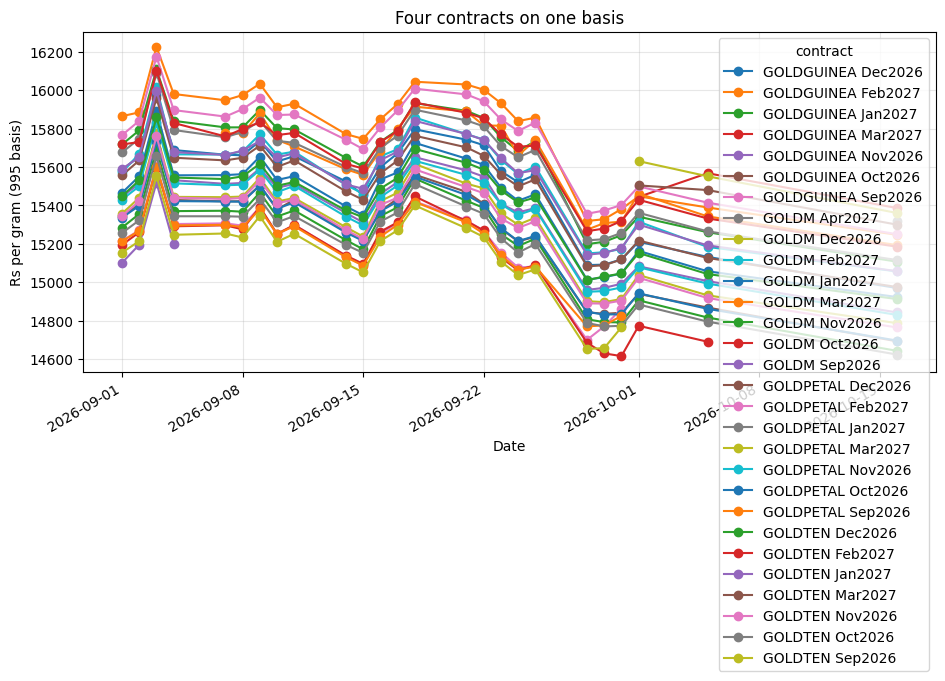

In [7]:
wide = df.pivot_table(index="Date", columns="contract", values="rs_per_g")
ax = wide.plot(figsize=(11, 5), marker="o"); ax.set_ylabel("Rs per gram (995 basis)"); ax.set_title("Four contracts on one basis"); plt.grid(alpha=.3); plt.show()

## Chart 2: spread vs its normal range (change A, B, K)

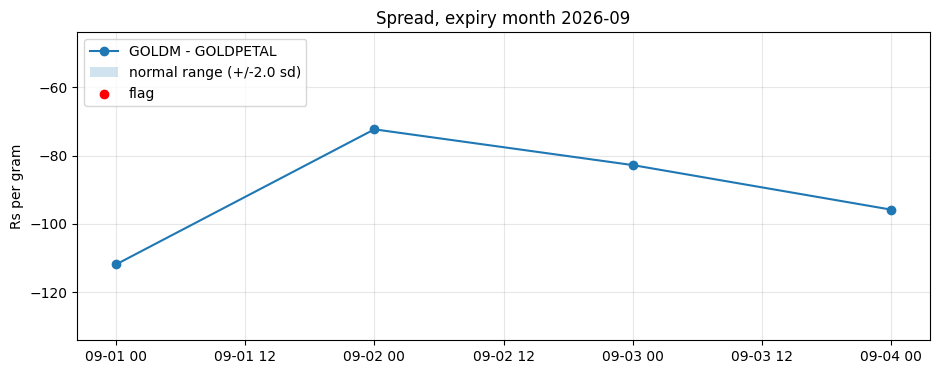

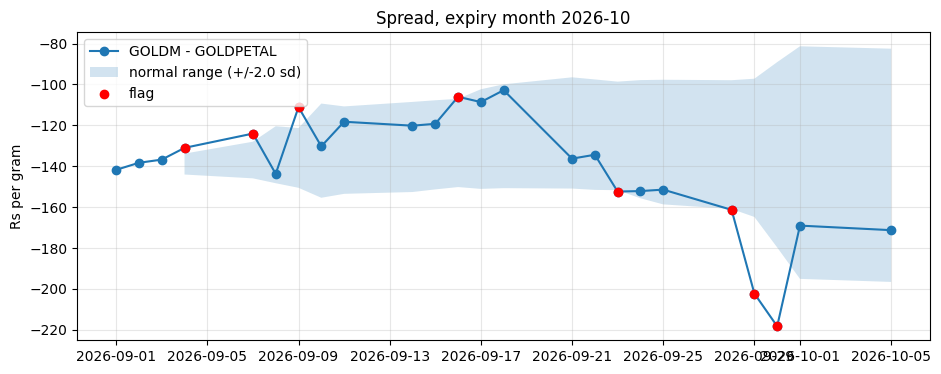

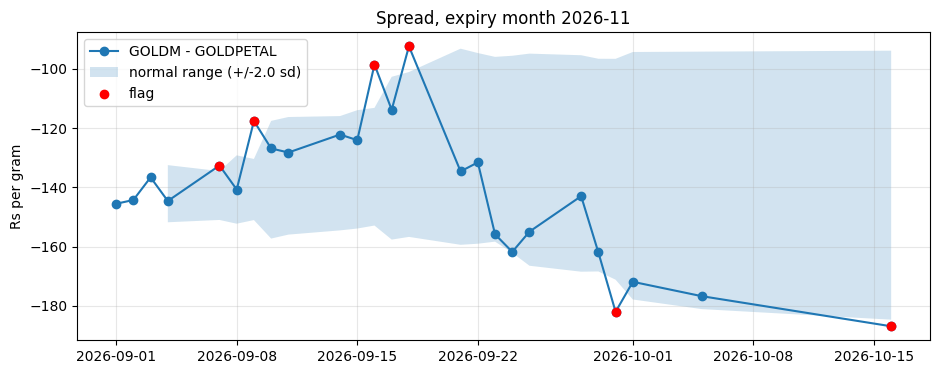

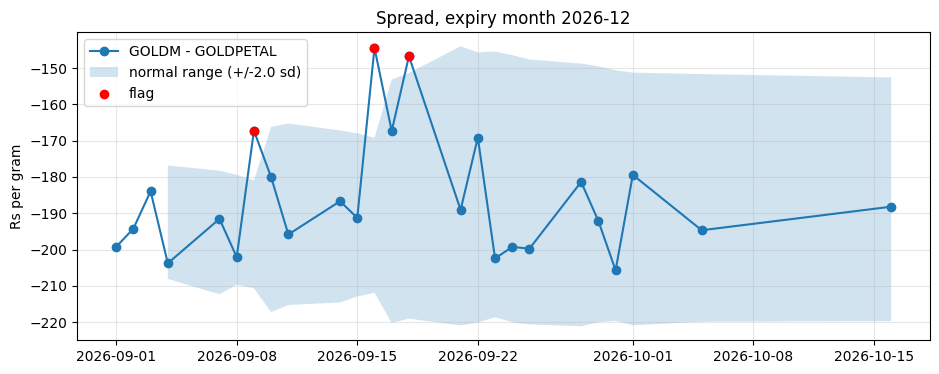

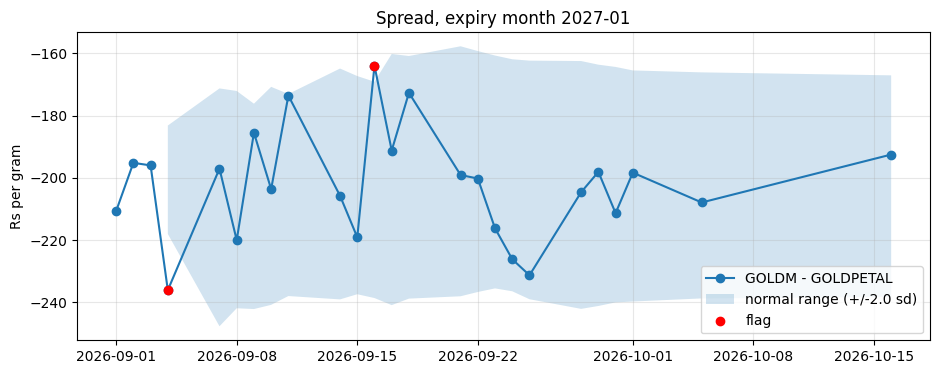

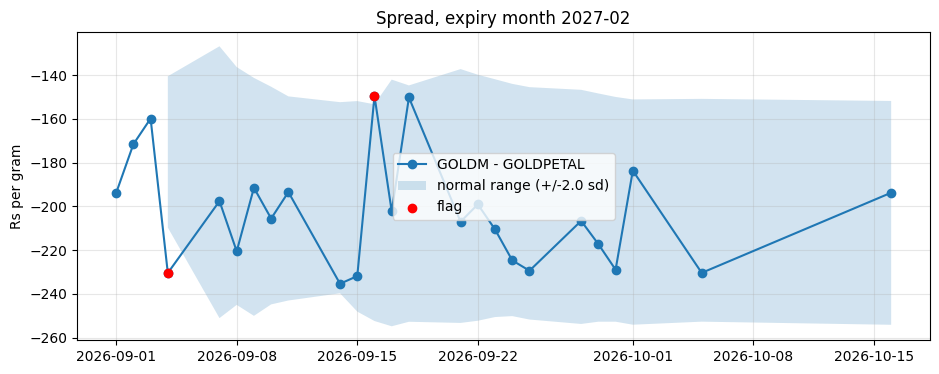

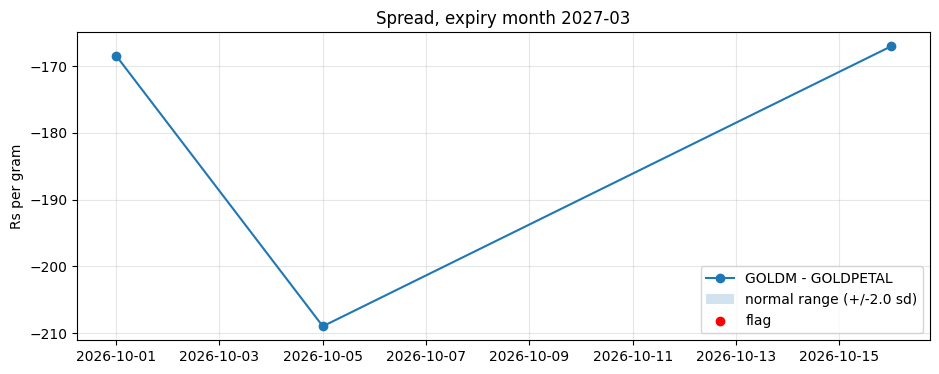

21 day(s) outside the normal range:


,Date,exp_month,spread,z
19,2026-09-04,2026-10,-131.002002,3.102039
24,2026-09-07,2026-10,-124.010010,2.887658
34,2026-09-09,2026-10,-111.077678,3.399139
59,2026-09-16,2026-10,-106.014214,2.091550
84,2026-09-23,2026-10,-152.366567,-2.049420
99,2026-09-28,2026-10,-161.320320,-2.027951
104,2026-09-29,2026-10,-202.276376,-4.216932
109,2026-09-30,2026-10,-218.268368,-3.701859
25,2026-09-07,2026-11,-132.669670,2.455503
35,2026-09-09,2026-11,-117.649349,4.484395


Costs and slippage are NOT applied: a flag is a candidate, not a trade.


In [8]:
A, B, K = "GOLDM", "GOLDPETAL", 2.0
sp = spread(df, A, B, k=K)
if sp.empty:
    print("No same-expiry-month overlap between these two contracts in your data.")
else:
    for m, g in sp.groupby("exp_month"):
        fig, ax = plt.subplots(figsize=(11, 4))
        ax.plot(g["Date"], g["spread"], marker="o", label=f"{A} - {B}")
        ax.fill_between(g["Date"], g["mean"] - K*g["std"], g["mean"] + K*g["std"], alpha=.2, label=f"normal range (+/-{K} sd)")
        ax.scatter(g[g["flag"]]["Date"], g[g["flag"]]["spread"], color="red", zorder=5, label="flag")
        ax.set_title(f"Spread, expiry month {m}"); ax.set_ylabel("Rs per gram"); ax.legend(); ax.grid(alpha=.3); plt.show()
    hits = sp[sp["flag"]]
    print("QUIET: no meaningful signal. (No edge is a valid result.)" if hits.empty else f"{len(hits)} day(s) outside the normal range:")
    if not hits.empty: display(hits[["Date", "exp_month", "spread", "z"]])
print("Costs and slippage are NOT applied: a flag is a candidate, not a trade.")